# Laboratorio Evaluado: WBCD y Evaluación Multimodelo

**Reto Autónomo: Clínica Oncológica**

Eres el Consultor IA de un hospital. El dataset WBCD contiene radios y perímetros de células. Debes entrenar k-NN y Árboles de Decisión, y validar qué pasa si no escalas los datos.

> **Idea general:** vamos a enseñarle a dos modelos a decidir si un tumor es **benigno** (no es cáncer) o **maligno** (es cáncer), usando medidas de las células.

## 1. Carga de Datos y Exploración

Primero importamos las librerías y cargamos los datos. El archivo no trae los nombres de las columnas, así que se los ponemos nosotros.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Cargamos el dataset desde UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"

# Nombres de las columnas: id, diagnosis y 30 medidas
# (10 medidas distintas x 3 versiones: promedio, error y peor valor)
medidas = ["radius", "texture", "perimeter", "area", "smoothness",
           "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
columnas = (["id", "diagnosis"]
            + [m + "_mean" for m in medidas]
            + [m + "_se" for m in medidas]
            + [m + "_worst" for m in medidas])

df_wbcd = pd.read_csv(url, header=None, names=columnas)

# Miramos las primeras filas y cuántos casos hay de cada tipo
print("Filas y columnas:", df_wbcd.shape)
print(df_wbcd["diagnosis"].value_counts())   # M = maligno, B = benigno
df_wbcd.head()

Filas y columnas: (569, 32)
diagnosis
B    357
M    212
Name: count, dtype: int64


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Preprocesamiento

Los modelos solo entienden números, así que convertimos la letra del diagnóstico: **M → 1** (maligno) y **B → 0** (benigno).

Luego separamos:
- **X**: las medidas de las células (lo que el modelo usa para decidir).
- **y**: el diagnóstico real (lo que queremos adivinar).

Finalmente dividimos en **train** (80%, con lo que el modelo aprende) y **test** (20%, para probarlo con casos que nunca vio).

In [2]:
# M -> 1, B -> 0
df_wbcd["diagnosis"] = df_wbcd["diagnosis"].map({"M": 1, "B": 0})

# X = medidas (quitamos id y diagnosis), y = diagnóstico
X = df_wbcd.drop(columns=["id", "diagnosis"])
y = df_wbcd["diagnosis"]

# 80% para entrenar, 20% para probar
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (455, 30)
Datos de prueba: (114, 30)


## 3. Escalamiento (Solo para k-NN)

Las medidas están en escalas muy distintas. Por ejemplo, el **área** vale cientos, pero la **suavidad** vale 0.1. Mira el gráfico:

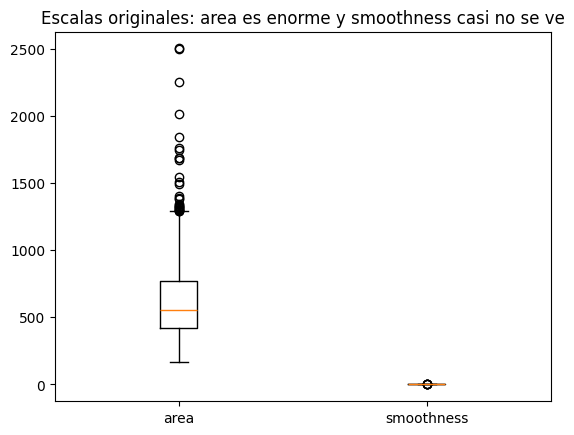

In [3]:
# Comparamos la escala de dos medidas
plt.boxplot([X_train["area_mean"], X_train["smoothness_mean"]])
plt.xticks([1, 2], ["area", "smoothness"])
plt.title("Escalas originales: area es enorme y smoothness casi no se ve")
plt.show()

`StandardScaler` pone todas las medidas en una escala parecida (alrededor de 0). Regla importante:
- `fit_transform` **solo en train** (aprende cómo escalar).
- `transform` **en test** (usa lo que aprendió, sin volver a aprender).

In [4]:
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)   # aprende y escala train
X_test_esc = scaler.transform(X_test)         # solo escala test

## 4. Modelado y Matrices de Confusión

Entrenamos los modelos y vemos qué tal les fue con los datos de prueba:
- **k-NN**: mira los 5 casos más parecidos y decide por mayoría. Usa datos **escalados**.
- **Árbol de decisión**: hace preguntas tipo "¿el área es mayor que X?". Usa datos **originales**.
- Además entrenamos un **k-NN sin escalar** para ver qué pasa.

In [5]:
# k-NN con datos escalados
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_esc, y_train)
pred_knn = knn.predict(X_test_esc)

# k-NN SIN escalar (para comparar)
knn_sin = KNeighborsClassifier(n_neighbors=5)
knn_sin.fit(X_train, y_train)
pred_knn_sin = knn_sin.predict(X_test)

# Árbol de decisión (no necesita escalar)
arbol = DecisionTreeClassifier(max_depth=4, random_state=42)
arbol.fit(X_train, y_train)
pred_arbol = arbol.predict(X_test)

# Matrices de confusión
print("k-NN escalado:\n", confusion_matrix(y_test, pred_knn))
print("\nk-NN sin escalar:\n", confusion_matrix(y_test, pred_knn_sin))
print("\nÁrbol de decisión:\n", confusion_matrix(y_test, pred_arbol))

k-NN escalado:
 [[68  3]
 [ 3 40]]

k-NN sin escalar:
 [[71  0]
 [ 5 38]]

Árbol de decisión:
 [[68  3]
 [ 3 40]]


### ¿Cómo leer una matriz de confusión?

```
                 Predijo Benigno   Predijo Maligno
Real Benigno         acierto         Falso Positivo
Real Maligno      Falso Negativo       acierto
```

Los números de la **diagonal** son aciertos. Los de afuera son errores. El más peligroso es el **Falso Negativo** (abajo a la izquierda).

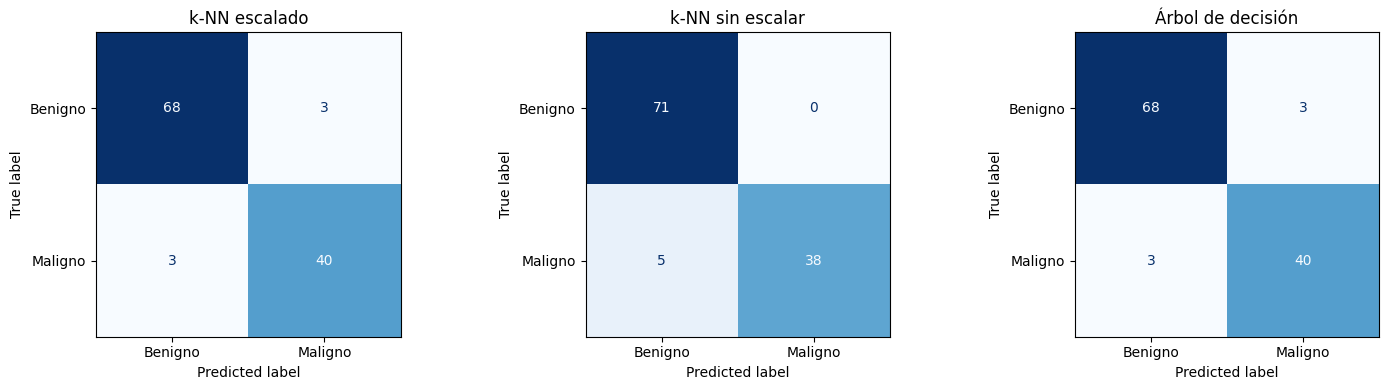

In [6]:
# Las mismas matrices, pero en dibujo
modelos = {"k-NN escalado": pred_knn,
           "k-NN sin escalar": pred_knn_sin,
           "Árbol de decisión": pred_arbol}

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, (nombre, pred) in zip(ejes, modelos.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Benigno", "Maligno"],
        cmap="Blues", ax=eje, colorbar=False)
    eje.set_title(nombre)
plt.tight_layout()
plt.show()

## Evaluación Teórica / Decisión de Negocios

**1. En este escenario médico, ¿qué implica un Error Tipo II (Falso Negativo) y por qué cuesta vidas?**

Un Falso Negativo es cuando el modelo dice que el tumor es **benigno**, pero en realidad es **maligno**. A la paciente se le dice "estás sana" cuando sí tiene cáncer.

Cuesta vidas porque no recibe tratamiento a tiempo y el cáncer sigue avanzando. En cambio, un Falso Positivo (decir "maligno" cuando era benigno) solo causa un susto y más exámenes, pero la paciente sigue sana. Por eso en medicina es preferible tener pocos falsos negativos, aunque haya algunos falsos positivos.

**2. ¿Por qué crees que el Árbol de Decisión no falló estrepitosamente incluso si no hubieses escalado los datos?**

Porque el árbol no calcula distancias. Solo hace preguntas simples sobre **una medida a la vez**, como "¿el área es mayor que 700?". Para eso solo importa qué valores son más grandes o más pequeños, no qué tan grande es la escala. Al escalar, el orden de los valores no cambia, por eso el árbol da lo mismo con o sin escalar.

k-NN, en cambio, mide **distancias** entre pacientes. Si una medida tiene números enormes (como el área), pesa mucho más que las demás y "tapa" a las otras. Por eso k-NN sí necesita escalar. En nuestros resultados, sin escalar dejó pasar 5 tumores malignos (falsos negativos), contra 3 cuando sí escalamos: menos aciertos justo donde más importa. (Si cambias el `random_state`, los números pueden variar un poco).